# CSE 4095 — Class 3: Regression and Model Error
Use AI to help write unfamiliar code, but verify and explain each modeling decision.

## Setup
Imports, then load the dataset and check its structure and missing values.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# keep_default_na=False stops pandas from reading the category "None" as missing.
# Only truly empty cells become NaN.
df = pd.read_csv("class1_student_habits.csv", keep_default_na=False, na_values=[""])
df.head()

,student_id,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes,quiz_average,exam_score
0,S001,1.3,7.7,71.8,8,Strong,No,0,67.0,64.6
1,S002,9.4,6.6,74.2,14,None,Yes,52,74.8,81.5
2,S003,11.2,6.1,70.3,15,Some,No,7,99.1,92.0
3,S004,10.8,7.6,77.1,16,Strong,No,12,86.4,100.0
4,S005,8.0,5.6,89.7,15,None,Yes,12,75.7,68.5


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 10 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   student_id                    250 non-null    str    
 1   study_hours_per_week          241 non-null    float64
 2   sleep_hours_per_night         238 non-null    float64
 3   attendance_rate               250 non-null    float64
 4   practice_problems_per_week    250 non-null    int64  
 5   prior_programming_experience  243 non-null    str    
 6   study_group                   250 non-null    str    
 7   commute_minutes               250 non-null    int64  
 8   quiz_average                  250 non-null    float64
 9   exam_score                    250 non-null    float64
dtypes: float64(5), int64(2), str(3)
memory usage: 19.7 KB


In [4]:
df.isna().sum()

student_id                       0
study_hours_per_week             9
sleep_hours_per_night           12
attendance_rate                  0
practice_problems_per_week       0
prior_programming_experience     7
study_group                      0
commute_minutes                  0
quiz_average                     0
exam_score                       0
dtype: int64

## Part 1 — Regression vs. Classification
Conceptual only, no code.

### Part 1 Questions

**1. Why is this a regression problem?**

**My answer:** Regression problems deal with continuous quantitative values, which is what exam_score, the target, is. 

**2. How is this different from the Class 2 classification problem?**

**My answer:** Classification deals with labels rather than strictly numbers, the classification of last class was high_exam_score, which was a Yes or No value if exam score was >= 80

**3. What information is lost when we convert exam_score into only Yes or No?**

**My answer:** The information is the specifics, how far above or below 80 the student got. A student could've had a 79.999999 and been in the NO group, when functionally they are the same as the >=80 students. 

**4. What kind of output should a regression model produce?**

**My answer:** A regression model should output a number on the same scale as the target, which is exam_score. One prediction per student.

## Part 2 — Understand the Target
Summary statistics, the distribution, and a check for unusual values in `exam_score`.

In [5]:
exam_score_stats = df["exam_score"].agg(["count", "mean", "median", "std", "min", "max"])
exam_score_stats.round(2).to_frame()

,exam_score
count,250.00
mean,77.16
median,76.95
std,10.33
min,51.40
max,100.00


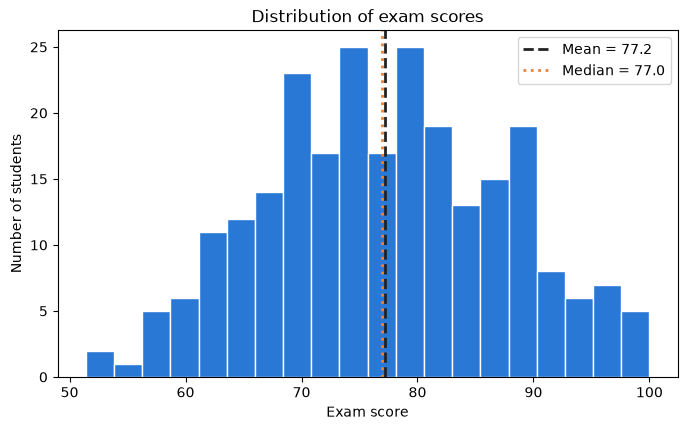

In [6]:
mean_score = df["exam_score"].mean()
median_score = df["exam_score"].median()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(df["exam_score"], bins=20, color="#2a78d6", edgecolor="white")
ax.axvline(mean_score, color="#222222", linestyle="--", linewidth=2, label=f"Mean = {mean_score:.1f}")
ax.axvline(median_score, color="#e8833a", linestyle=":", linewidth=2, label=f"Median = {median_score:.1f}")
ax.set_xlabel("Exam score")
ax.set_ylabel("Number of students")
ax.set_title("Distribution of exam scores")
ax.legend()
plt.show()

In [7]:
# 1.5 IQR rule: report unusual scores, but keep them in the data
q1 = df["exam_score"].quantile(0.25)
q3 = df["exam_score"].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

unusually_low = df[df["exam_score"] < lower_fence]
unusually_high = df[df["exam_score"] > upper_fence]

print(f"Q1 = {q1:.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f}")
print(f"Fences: below {lower_fence:.2f} or above {upper_fence:.2f}")
print(f"Scores below the lower fence: {len(unusually_low)}")
print(f"Scores above the upper fence: {len(unusually_high)}")

Q1 = 69.50, Q3 = 84.97, IQR = 15.47
Fences: below 46.29 or above 108.19
Scores below the lower fence: 0
Scores above the upper fence: 0


### Part 2 Questions

**1. Describe the distribution of exam scores.**

**My answer:** Mean  77.2, Median  77.0. Roughly symmetric distribution, and the stdev spread is 10.3 points, so a typical student is within 10 points of the average. 

**2. Are there unusually low or high values?**

**My answer:** The lowest score is 51.4, but this is above the lower fence of 46.3, and 100, the highest score, is below the upper fence of 108.2. 

**3. Why is it useful to understand the target before trying to predict it?**

**My answer:** Trying to understand the target helps to set up the baseline, and also sets error bounds and expectations. Understanding the target can also help to catch data errors early, like missing values or outliers. 

## Part 3 — Explore One Relationship
`study_hours_per_week` vs. `exam_score`. The trend line is for visual reference only, it is not one of our models.

Pearson correlation: 0.516 (n = 241 students)


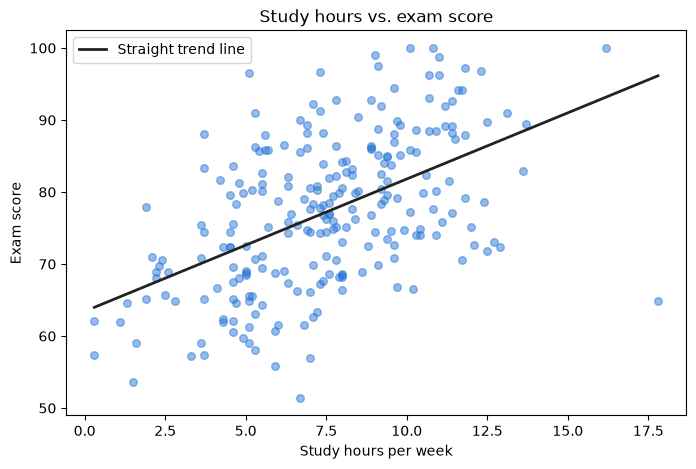

In [8]:
study_and_score = df[["study_hours_per_week", "exam_score"]].dropna()
study_hours = study_and_score["study_hours_per_week"]
scores = study_and_score["exam_score"]

correlation = study_hours.corr(scores)
print(f"Pearson correlation: {correlation:.3f} (n = {len(study_and_score)} students)")

slope, intercept = np.polyfit(study_hours, scores, 1)
line_x = np.linspace(study_hours.min(), study_hours.max(), 100)
line_y = slope * line_x + intercept

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(study_hours, scores, color="#2a78d6", alpha=0.5, s=30)
ax.plot(line_x, line_y, color="#222222", linewidth=2, label="Straight trend line")
ax.set_xlabel("Study hours per week")
ax.set_ylabel("Exam score")
ax.set_title("Study hours vs. exam score")
ax.legend()
plt.show()

> **Reminder:** correlation is not causation. A relationship between study hours and exam scores does not prove that studying more *causes* higher scores. Other factors (motivation, prior experience) could drive both.

### Part 3 Questions

**1. Does there appear to be a relationship?**

**My answer:** Yes, there appears to be a relationship. r=0.52 is above zero, but not close to 1. There's a lot of scatter around the line, students who study the same amount can differ substantially. 

**2. Is the relationship positive or negative?**

**My answer:** The relationship is positive, since people that study more tend to score higher. 

**3. Does it appear approximately linear?**

**My answer:** Roughly linear over most of the range, about 3-11 hours are where the averages climb. 

**4. Are there students who do not follow the general pattern?**

**My answer:** Yes, there are a good amount of students more than 15 points away from the trend line. 

## Part 4 — Choose the Base Features
Pick the feature columns for the main model and sort them into numerical and categorical by dtype.

In [9]:
# Intentionally excluded: student_id, exam_score, and quiz_average.
# quiz_average will be tested in Part 14.
base_features = [
    "study_hours_per_week",
    "sleep_hours_per_night",
    "attendance_rate",
    "practice_problems_per_week",
    "prior_programming_experience",
    "study_group",
    "commute_minutes",
]

numeric_features = df[base_features].select_dtypes(include="number").columns.tolist()
categorical_features = df[base_features].select_dtypes(exclude="number").columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['study_hours_per_week', 'sleep_hours_per_night', 'attendance_rate', 'practice_problems_per_week', 'commute_minutes']
Categorical features: ['prior_programming_experience', 'study_group']


## Part 5 — Training and Test Sets
One 80/20 split, reused by every model in this notebook. `quiz_average` is included in the split so Part 14 uses exactly the same students.

In [10]:
rows_before = len(df)
df = df.dropna(subset=["exam_score"])
print(f"Rows dropped for missing exam_score: {rows_before - len(df)}")

X_all = df[base_features + ["quiz_average"]]
y = df["exam_score"]

X_train_all, X_test_all, y_train, y_test = train_test_split(
    X_all, y, test_size=0.2, random_state=42
)

X_train = X_train_all[base_features]
X_test = X_test_all[base_features]

print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_test: ", X_test.shape, " y_test: ", y_test.shape)
print(f"Mean exam_score, train: {y_train.mean():.2f}")
print(f"Mean exam_score, test:  {y_test.mean():.2f}")

Rows dropped for missing exam_score: 0
X_train: (200, 7)  y_train: (200,)
X_test:  (50, 7)  y_test:  (50,)
Mean exam_score, train: 77.73
Mean exam_score, test:  74.89


### Part 5 Questions

**1. What is the training set used for?**

**My answer:** The training set is used for training the model. The model uses this set to learn patterns and learn predictions.

**2. What is the test set used for?**

**My answer:** The test set is used as the answer key, the final check. The students stand in for future students the model hasn't seen. Predicting these scores, and comparing to the real ones to estimate error.

**3. Why should the model not be trained using the test set?**

**My answer:** This can cause leakage, since the model will have been trained of data it shouldn't have seen. This makes the model optimistic. 

**4. Why should different experiments use the same split when comparing them fairly?**

**My answer:** Different splits are the same as different test students. Some slpits can happen to have harder or easier students. A difference in score could just be the RNG of the split, and not the accuracy of the model. 

## Part 6 — Preprocessing
A function that builds the preprocessing step, so later Parts can make a fresh one for different feature lists.

In [11]:
def build_preprocessor(numeric_cols, categorical_cols, scale=True):
    """Return a ColumnTransformer for numeric and categorical columns.

    Numeric: fill missing with the median, then standardize (unless scale=False).
    Categorical: fill missing with the most frequent value, then one-hot encode.
    """
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scaler", StandardScaler()))

    numeric_transformer = Pipeline(numeric_steps)
    categorical_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])

    return ColumnTransformer([
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols),
    ])


# Medians, means, standard deviations, and categories are learned when the
# preprocessor is fit. Inside a pipeline it is fit on the training data only,
# so the test set never influences these statistics.
preprocessor = build_preprocessor(numeric_features, categorical_features)
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

### Part 6 Questions

**1. Why do we handle numerical and categorical variables differently?**

**My answer:** We handle these different because our models are based on regression, which only handle numbers. 

**2. What does StandardScaler do?**

**My answer:** StandardScaler subtracts a column's mean value, and divides by the stdev. After the column has mean 0 and std 1. Value of +1 means one stdev above average. 

**3. What does one-hot encoding do?**

**My answer:** one-hot encoding turns a categorical column into a 0/1 colum per category. A student with "some" gets None = 0, Some = 1, Strong = 0. Strong = None = 0, Some = 0, Strong = 1.

**4. Why should preprocessing be learned from the training data rather than the entire dataset?**

**My answer:** Preprocessing should be learned from the training data because there are included the 50 test students within the entire dataset. This causes a small model leak.

## Part 7 — Mean Baseline
Predict the training-set average for every test student. Any real model has to beat this.

In [12]:
baseline_value = y_train.mean()
y_pred_baseline = np.full(len(y_test), baseline_value)
print(f"Baseline prediction for every test student: {baseline_value:.2f}")


def regression_metrics(name, y_true, y_pred):
    """Return MAE, MSE, RMSE, and R² for one model, rounded to 3 decimals."""
    return {
        "Model": name,
        "MAE": round(mean_absolute_error(y_true, y_pred), 3),
        "MSE": round(mean_squared_error(y_true, y_pred), 3),
        "RMSE": round(np.sqrt(mean_squared_error(y_true, y_pred)), 3),
        "R²": round(r2_score(y_true, y_pred), 3),
    }


results = [regression_metrics("Mean baseline", y_test, y_pred_baseline)]
pd.DataFrame(results)

Baseline prediction for every test student: 77.73


,Model,MAE,MSE,RMSE,R²
0,Mean baseline,7.659,96.08,9.802,-0.091


### Part 7 Questions

**1. Why is this baseline useful?**

**My answer:** This baseline is useful because it's the no learning reference point. This baseline only uses average scores, and it will show if the model is improving / learning if it gets past this baseline. 

## Part 8 — Linear Regression
Preprocessing + LinearRegression in one pipeline, fit on the training data only.

In [13]:
lin_reg = Pipeline([
    ("prep", preprocessor),
    ("model", LinearRegression()),
])

lin_reg.fit(X_train, y_train)
y_pred_lr = lin_reg.predict(X_test)

first_10 = pd.DataFrame({
    "actual": y_test,
    "predicted": y_pred_lr.round(1),
    "difference": (y_test - y_pred_lr).round(1),
}).head(10)
first_10

,actual,predicted,difference
142,72.5,78.1,-5.6
6,68.0,68.4,-0.4
97,78.3,82.0,-3.7
60,84.0,87.0,-3.0
112,69.0,67.2,1.8
181,74.8,75.4,-0.6
197,69.1,65.5,3.6
184,71.5,73.7,-2.2
9,70.5,78.1,-7.6
104,79.4,76.3,3.1


### Part 8 Questions

**1. What does .fit() do?**

**My answer:** .fit() learns from the training data.Runs every step in order on X_train and Y_Train

**2. What does .predict() do?**

**My answer:** .predict() Applies what was learned to new data, without learning anything new. 

**3. Why can predictions contain decimals when original scores are whole numbers?**

**My answer:** Predictions can contain decimals because most scores are not whole numbers. A linear model's prediction is intercept + coefficiencts x feature values, and the coeffs are decimals, so the result is almost never a round number. 

## Part 9 — Evaluate Prediction Error
Compare Linear Regression with the mean baseline on the same 50 test students.

In [14]:
results.append(regression_metrics("Linear Regression", y_test, y_pred_lr))
pd.DataFrame(results)

,Model,MAE,MSE,RMSE,R²
0,Mean baseline,7.659,96.080,9.802,-0.091
1,Linear Regression,5.774,69.698,8.349,0.209


**Metric definitions** (all computed on the test set):

- **MAE** (mean absolute error): the average size of the errors, ignoring sign. Same units as the target (exam-score points).
- **MSE** (mean squared error): the average of the squared errors. Units are points², and big errors count much more.
- **RMSE** = √MSE: brings MSE back to exam-score points. Still weights big errors more than MAE does.
- **R²**: how much better the model is than always predicting the mean of the actual scores. 1 = perfect, 0 = no better than the mean, below 0 = worse than the mean.

### Part 9 Questions

**1. Which metric is easiest to explain in exam-score points?**

**My answer:** MAE is easiest to explain, On average, the prediction is off by about 5.8 points. 

**2. Why does MSE penalize large errors more than MAE?**

**My answer:** MAE penalizes less, because MAE counts every point of error the same, where as MSE squares each error before averaging. 

**3. Why might RMSE be easier to interpret than MSE?**

**My answer:** RMSE might be easier to interpret because RMSE takes the square root, so it's back in the same scale as the scores and comparable with MAE, while MSE is in squared points. 

**4. Did Linear Regression outperform the baseline?**

**My answer:** Yes, on every metric on this test set, it outperformed the baseline. MAE performed about 2 points better on average, RMSE 1.55 points, and R^2 was .209 vs -.091. 

**5. What does your R² tell you?**

**My answer:** R^2 tells you that the models explains around R^2 of the variation in test scores. R^2 = .209, so the models explains about 21% of the variation in test scores, and why the happen. A lot of the variation is still unexplained. 

## Part 10 — Actual vs Predicted
Each point is one test student. Points on the dashed line were predicted perfectly.

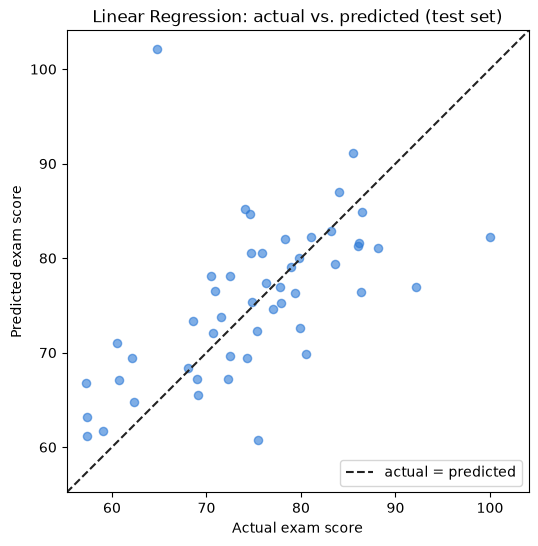

In [15]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, y_pred_lr, color="#2a78d6", alpha=0.6, s=35)

low = min(y_test.min(), y_pred_lr.min()) - 2
high = max(y_test.max(), y_pred_lr.max()) + 2
ax.plot([low, high], [low, high], color="#222222", linestyle="--", linewidth=1.5, label="actual = predicted")

ax.set_xlim(low, high)
ax.set_ylim(low, high)
ax.set_aspect("equal")
ax.set_xlabel("Actual exam score")
ax.set_ylabel("Predicted exam score")
ax.set_title("Linear Regression: actual vs. predicted (test set)")
ax.legend()
plt.show()

### Part 10 Questions

**1. What would a perfect model look like?**

**My answer:** A perfect mode would look like every point would land perfectly on the dashed diagonal line. All residuals 0, MAE and RMSE 0, R^2 = 1.

**2. Are most points close to the diagonal?**

**My answer:** Most points are somewhat close, but there is a clear scatter. 

**3. Where does the model make larger errors?**

**My answer:** The model makes larger errors at the extremes, where high scores get under predicted, and low scores get over predicted. 

## Part 11 — Residuals
Residual = actual − predicted.

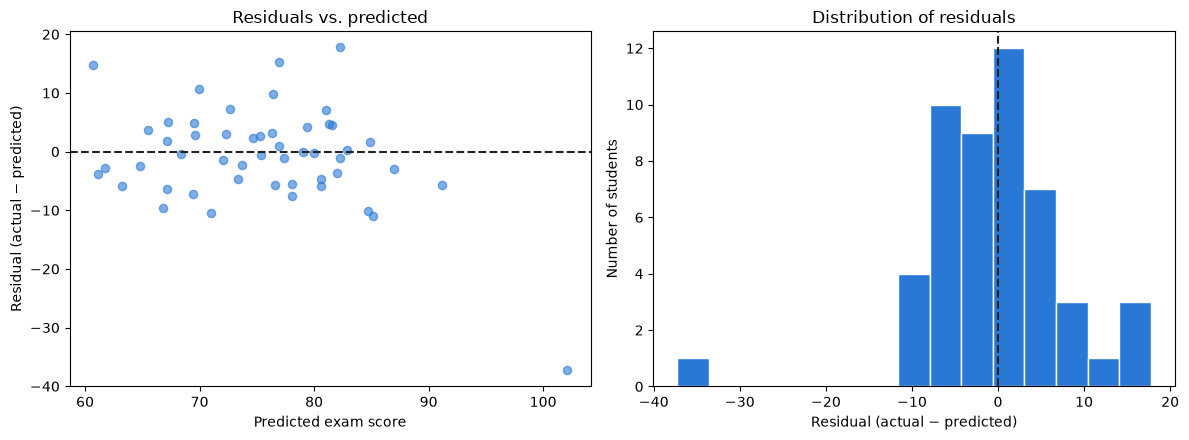

In [16]:
residuals_lr = y_test - y_pred_lr

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(12, 4.5))

ax_left.scatter(y_pred_lr, residuals_lr, color="#2a78d6", alpha=0.6, s=35)
ax_left.axhline(0, color="#222222", linestyle="--", linewidth=1.5)
ax_left.set_xlabel("Predicted exam score")
ax_left.set_ylabel("Residual (actual − predicted)")
ax_left.set_title("Residuals vs. predicted")

ax_right.hist(residuals_lr, bins=15, color="#2a78d6", edgecolor="white")
ax_right.axvline(0, color="#222222", linestyle="--", linewidth=1.5)
ax_right.set_xlabel("Residual (actual − predicted)")
ax_right.set_ylabel("Number of students")
ax_right.set_title("Distribution of residuals")

plt.tight_layout()
plt.show()

### Part 11 Questions

**1. What does a positive residual mean?**

**My answer:** A positive residual means Actual is > predicted. The student scored higher than expected. 

**2. What does a negative residual mean?**

**My answer:** Negative residual is the opposite, Actual < predicted. Meaning the student scored worse than expected. 

**3. What does a residual near zero mean?**

**My answer:** A residual near 0 means the prediction was spot on, the student scored almost exactly as the model predicted. 

**4. Do you see any pattern?**

**My answer:** Yes, The histogram chart is centered near 0, and is rougle bell shaped from around -11 to +18. There is one clear outlier in the bottom right, which is the only prediction above 100. 

## Part 12 — Largest Errors
The 10 test students with the biggest absolute errors, and how their features compare with the whole test set.

In [17]:
error_df = X_test.copy()
error_df["actual"] = y_test
error_df["predicted"] = y_pred_lr.round(1)
error_df["residual"] = residuals_lr.round(1)
error_df["absolute_error"] = residuals_lr.abs().round(1)

top_10_errors = error_df.sort_values("absolute_error", ascending=False).head(10)
top_10_errors

,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes,actual,predicted,residual,absolute_error
173,17.8,6.9,98.1,0,Strong,Yes,36,64.8,102.1,-37.3,37.3
108,10.1,7.3,91.6,25,None,Yes,0,100.0,82.2,17.8,17.8
19,7.1,NaN,90.0,14,Some,Yes,24,92.2,76.9,15.3,15.3
69,4.6,7.4,64.3,9,None,Yes,30,75.5,60.7,14.8,14.8
240,10.4,6.6,91.2,20,Some,No,0,74.1,85.2,-11.1,11.1
196,7.0,6.3,98.3,3,None,No,39,80.5,69.9,10.6,10.6
15,4.6,6.5,88.0,0,Strong,Yes,15,60.5,71.0,-10.5,10.5
222,9.5,5.8,70.9,22,Strong,No,27,74.6,84.7,-10.1,10.1
67,5.3,6.2,98.2,22,Some,No,16,86.3,76.4,9.9,9.9
159,3.3,7.4,72.0,0,Strong,No,30,57.2,66.8,-9.6,9.6


In [18]:
feature_means = pd.DataFrame({
    "top 10 errors": top_10_errors[numeric_features].mean(),
    "whole test set": error_df[numeric_features].mean(),
}).round(2)
feature_means

,top 10 errors,whole test set
study_hours_per_week,7.97,6.74
sleep_hours_per_night,6.71,7.16
attendance_rate,86.26,85.73
practice_problems_per_week,11.50,15.58
commute_minutes,21.70,21.68


**Case 1 (row ___):** What the data show: Actual was 64.8, model predicted 102.1 / My hypothesis about why: Inefficient exam practice may not produce good exam results even if the student studied a lot.

**Case 2 (row ___):** What the data show: Actual was 100, model predicted 82.2 / My hypothesis about why: Student might has ability that the model does not capture, this is supported by the high quiz average of this student. 

> **Reminder:** a hypothesis is a possible explanation, not proof of cause. These are single students, and the data can't show *why* the model missed them.

## Part 13 — Coefficients
What the fitted Linear Regression learned for each column after preprocessing.

In [19]:
feature_names = lin_reg.named_steps["prep"].get_feature_names_out()
linear_model = lin_reg.named_steps["model"]

coef_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": linear_model.coef_.round(3),
}).sort_values("coefficient", ascending=False)

print(f"Intercept: {linear_model.intercept_:.3f}")
coef_table

Intercept: 78.562


,feature,coefficient
0,num__study_hours_per_week,5.933
7,cat__prior_programming_experience_Strong,5.060
3,num__practice_problems_per_week,3.169
2,num__attendance_rate,1.976
1,num__sleep_hours_per_night,1.329
4,num__commute_minutes,0.528
8,cat__study_group_No,0.120
9,cat__study_group_Yes,-0.120
6,cat__prior_programming_experience_Some,-0.192
5,cat__prior_programming_experience_None,-4.867


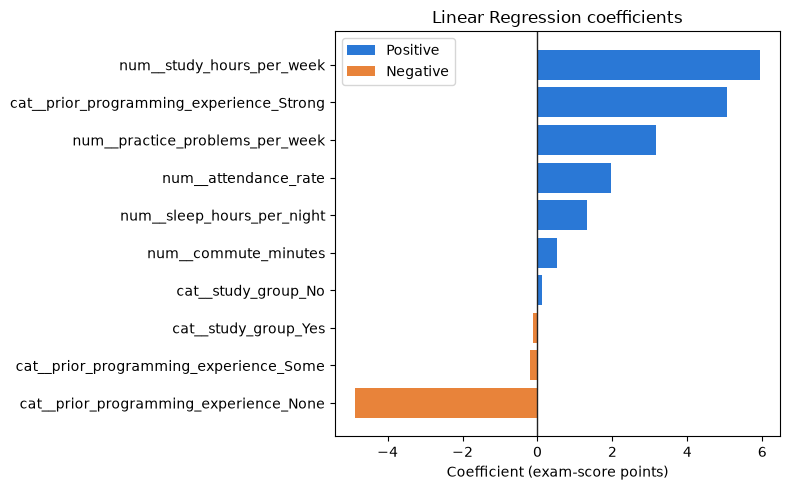

In [20]:
positive = coef_table[coef_table["coefficient"] >= 0]
negative = coef_table[coef_table["coefficient"] < 0]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(positive["feature"], positive["coefficient"], color="#2a78d6", label="Positive")
ax.barh(negative["feature"], negative["coefficient"], color="#e8833a", label="Negative")
ax.axvline(0, color="#222222", linewidth=1)
ax.invert_yaxis()
ax.set_xlabel("Coefficient (exam-score points)")
ax.set_title("Linear Regression coefficients")
ax.legend()
plt.tight_layout()
plt.show()

**How to read the coefficients:**

- **Numeric features** (`num__...`) were standardized, so each coefficient is the change in predicted score for a **one standard deviation** increase in that feature, holding the others fixed.
- **One-hot features** (`cat__...`) compare categories of the same feature. Our encoder keeps every category (none is dropped), so there's no single reference category. Compare the differences within a feature, for example `Strong` minus `None`.
- Because of this, numeric and one-hot magnitudes aren't perfectly comparable.

### Part 13 Questions

**1. Which features have positive coefficients?**

**My answer:** study hours, prior experience Strong, practice problems per week, attendance rate, sleep hours per night, commute minuts, study group No all have positive coefficients. 

**2. Which features have negative coefficients?**

**My answer:** Study group yes, prior programming experience Some, and prior programming experience None have negative coefficients. 

**3. Which features have relatively large magnitudes?**

**My answer:** Study hours per week, and prior programming experience strong have large magnitudes to their coefficients. 

**4. What does a positive coefficient mean in this fitted model?**

**My answer:** A positive coefficient overall means a higher predicted exam score based on the magnitude. 

> **Reminder:** coefficients are not causal effects. They describe patterns the model found in this data, with the other features held fixed. They don't show what would happen if a student changed a habit.

## Part 14 — Add quiz_average
Same students, same split. Only the feature list changes.

**Hypothesis:** I expect adding quiz_average to reduce MAE and RMSE and increase R², because quiz scores measure the same course knowledge the final exam tests, so they are likely strongly related to exam_score.

In [21]:
features_quiz = base_features + ["quiz_average"]
numeric_features_quiz = numeric_features + ["quiz_average"]

lin_reg_quiz = Pipeline([
    ("prep", build_preprocessor(numeric_features_quiz, categorical_features)),
    ("model", LinearRegression()),
])

lin_reg_quiz.fit(X_train_all[features_quiz], y_train)
y_pred_quiz = lin_reg_quiz.predict(X_test_all[features_quiz])

results.append(regression_metrics("Linear Regression + quiz_average", y_test, y_pred_quiz))

results_df = pd.DataFrame(results).set_index("Model")
results_df.loc[["Mean baseline", "Linear Regression", "Linear Regression + quiz_average"], ["MAE", "RMSE", "R²"]]

,MAE,RMSE,R²
Model,,,
Mean baseline,7.659,9.802,-0.091
Linear Regression,5.774,8.349,0.209
Linear Regression + quiz_average,4.749,6.231,0.559


### Part 14 Questions

**1. Did MAE improve?**

**My answer:**

**2. Did RMSE improve?**

**My answer:**

**3. Did R² improve?**

**My answer:**

**4. Was the hypothesis supported?**

**My answer:**

**5. Would quiz_average be available when the prediction is made? (Discuss predicting after quizzes vs before any quizzes.)**

**My answer:**

## Part 15 — Random Forest
Default settings, base features only, same split.

In [22]:
# Scaling is harmless but unnecessary for trees: splits depend on the order of
# values, not their units. It stays so every model gets the same preprocessing.
rf_reg = Pipeline([
    ("prep", build_preprocessor(numeric_features, categorical_features)),
    ("model", RandomForestRegressor(random_state=42)),
])

rf_reg.fit(X_train, y_train)
y_pred_rf = rf_reg.predict(X_test)

results.append(regression_metrics("Random Forest", y_test, y_pred_rf))

results_df = pd.DataFrame(results).set_index("Model")
results_df.loc[["Mean baseline", "Linear Regression", "Random Forest"], ["MAE", "RMSE", "R²"]]

,MAE,RMSE,R²
Model,,,
Mean baseline,7.659,9.802,-0.091
Linear Regression,5.774,8.349,0.209
Random Forest,6.311,8.003,0.273


### Part 15 Questions

**1. Which model has the lowest MAE?**

**My answer:**

**2. Which model has the lowest RMSE?**

**My answer:**

**3. Which model has the highest R²?**

**My answer:**

**4. Did the more complicated model necessarily perform better?**

**My answer:**

> **Reminder:** these conclusions apply only to this dataset and this one train/test split. With 50 test students, a different split could rank the models differently.

## Part 16 — Scaling and Random Forests
Demo on **training data only**: the same small tree on `study_hours_per_week`, raw vs. standardized.

In [23]:
demo = X_train[["study_hours_per_week"]].copy()
demo["exam_score"] = y_train
demo = demo.dropna()

hours_raw = demo[["study_hours_per_week"]]
demo_scaler = StandardScaler()
hours_scaled = demo_scaler.fit_transform(hours_raw)

tree_raw = DecisionTreeRegressor(max_depth=2, random_state=42)
tree_scaled = DecisionTreeRegressor(max_depth=2, random_state=42)
tree_raw.fit(hours_raw, demo["exam_score"])
tree_scaled.fit(hours_scaled, demo["exam_score"])

# Leaf nodes have threshold -2 (no split), so keep only real split thresholds
raw_thresholds = tree_raw.tree_.threshold[tree_raw.tree_.feature >= 0]
scaled_thresholds = tree_scaled.tree_.threshold[tree_scaled.tree_.feature >= 0]
print("Raw thresholds (hours):     ", raw_thresholds.round(3))
print("Standardized thresholds:    ", scaled_thresholds.round(3))

same_predictions = np.allclose(tree_raw.predict(hours_raw), tree_scaled.predict(hours_scaled))
print("Identical training predictions:", same_predictions)

# Undo the scaling: original = scaled * std + mean
converted_back = scaled_thresholds * demo_scaler.scale_[0] + demo_scaler.mean_[0]
print("Standardized thresholds converted back to hours:", converted_back.round(3))

Raw thresholds (hours):      [ 8.05  5.35 10.65]
Standardized thresholds:     [ 0.128 -0.819  1.04 ]
Identical training predictions: True
Standardized thresholds converted back to hours: [ 8.05  5.35 10.65]


**My explanation: Does RandomForestRegressor require StandardScaler? Why or why not?**



## Part 17 — Experiment: Linear Regression with vs without scaling
Same features, same split, same model. The only change is `scale=False`. Run once.

**Hypothesis:** I expect Linear Regression without StandardScaler to produce essentially the same MAE, RMSE, and R² as the scaled version, because ordinary least squares compensates for a feature's scale by adjusting its coefficient. Scaling changes the coefficient values but not the predictions.

In [24]:
lin_reg_unscaled = Pipeline([
    ("prep", build_preprocessor(numeric_features, categorical_features, scale=False)),
    ("model", LinearRegression()),
])

lin_reg_unscaled.fit(X_train, y_train)
y_pred_unscaled = lin_reg_unscaled.predict(X_test)

results.append(regression_metrics("Linear Regression (no scaling)", y_test, y_pred_unscaled))

results_df = pd.DataFrame(results).set_index("Model")
results_df.loc[["Linear Regression", "Linear Regression (no scaling)"], ["MAE", "RMSE", "R²"]]

,MAE,RMSE,R²
Model,,,
Linear Regression,5.774,8.349,0.209
Linear Regression (no scaling),5.774,8.349,0.209


In [25]:
compare_features = ["study_hours_per_week", "attendance_rate", "commute_minutes"]

scaled_coefs = pd.Series(
    lin_reg.named_steps["model"].coef_,
    index=lin_reg.named_steps["prep"].get_feature_names_out(),
)
unscaled_coefs = pd.Series(
    lin_reg_unscaled.named_steps["model"].coef_,
    index=lin_reg_unscaled.named_steps["prep"].get_feature_names_out(),
)

coef_compare = pd.DataFrame({
    "scaled (per 1 std)": [scaled_coefs[f"num__{f}"] for f in compare_features],
    "unscaled (per 1 unit)": [unscaled_coefs[f"num__{f}"] for f in compare_features],
}, index=compare_features).round(3)
coef_compare

,scaled (per 1 std),unscaled (per 1 unit)
study_hours_per_week,5.933,2.114
attendance_rate,1.976,0.207
commute_minutes,0.528,0.029


**Result, comparison with the original model, and whether the evidence supports my hypothesis:**



## 14. Your experiment and AI Reflection
State your expectation before running the experiment. Then summarize the evidence and reflect on one AI suggestion you evaluated.

In [26]:
# TODO: your experiment
